In [5]:
%load_ext autoreload
%autoreload 2

In [4]:
import sys
import warnings
warnings.simplefilter("ignore", UserWarning)

In [2]:
import torch
import os
import matplotlib.pyplot as plt
import random
from tqdm.auto import tqdm
import numpy as np
from torchvision import datasets, transforms
import torch.nn as nn
from torch.utils.data import Subset
import matplotlib.colors as mcolors

In [7]:
sys.path.insert(0, '.')
sys.path.append("..")
sys.path.append("../src")

from plot_utils import (
    plot_loss_acc,
    plot_train_val_loss_acc_separately,
    plot_loss_acc_difference,
    plot_var_acc_legends,
    plot_similar_indices
)

from utils import (
    random_p_data,
    concat_ckpt_metrics,
    create_influences_dict,
    top_last_influences,
    create_inf_int_distances,
    create_inter_entropies,
    create_inner_entropies,
    calc_pairwise_euclideans,
    calc_dist_inf_to_others,
    calc_volumes,
    pairwise_similarity,
    top_inf_indices,
    tsne_all_dataset,
    plt_decision_boundary,
)

from src.utils import load_checkpoint, random_p_data

In [8]:
dir_data="../data/"
dir_tensors = os.path.join("../influences/mnist", "mnist_2025-03-29_14-12-21")
dir_ckpt = "../checkpoint/"
dir_subset = os.path.join(dir_data,"subset_indices/mnist")
num_epochs = 100
ckpt_min = 1
ckpt_max = 100
p = 0.05
epochs_range = range(1, num_epochs + 1)
checkpoint_labels =  list([1, 2, 3, 5, 7, 10, 15, 20, 40, 60, 80, 100])

In [9]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1)) 
])
subset_indices = torch.load(f"{dir_subset}/train_subset_indices.pt")
mnist_train = datasets.MNIST(dir_data, train=True, download=False, transform=transform)
mnist_train = Subset(mnist_train, subset_indices)

In [10]:
save_objs_dict = torch.load(f"{dir_tensors}/accuracies_and_losses.pt", weights_only=False)

train_losses = save_objs_dict["model_eval_obj"].train_losses
validation_losses = save_objs_dict["model_eval_obj"].validation_losses
accuracies = save_objs_dict["model_eval_obj"].accuracies

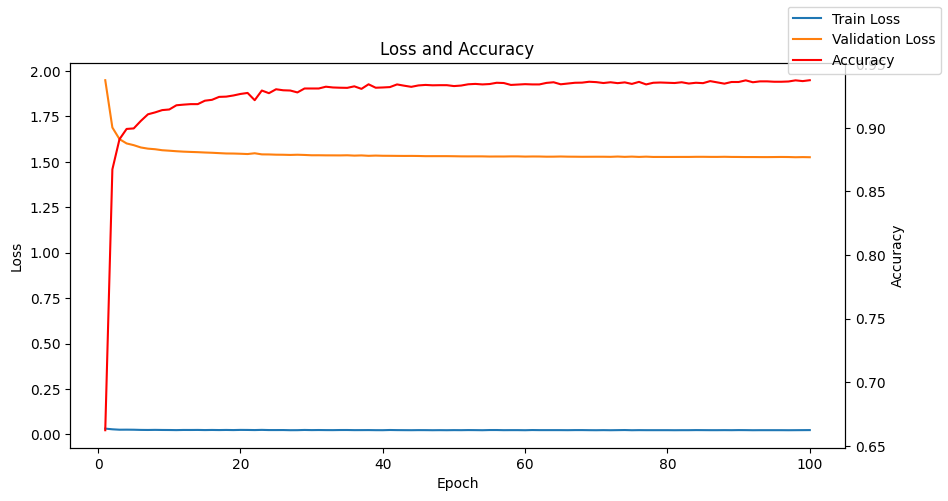

In [11]:
plot_loss_acc(epochs_range, train_losses, validation_losses, accuracies)

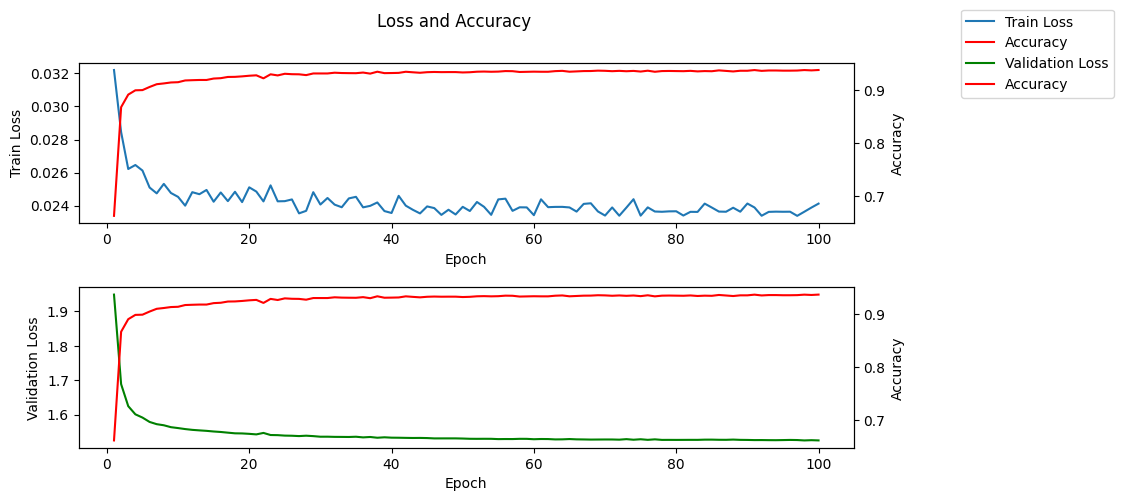

In [12]:
plot_train_val_loss_acc_separately(epochs_range, train_losses, validation_losses, accuracies)

# Influences

In [13]:
x_vals = list(range(1, num_epochs + 1))
num_data = len(mnist_train)
checkpoints_filepaths = [os.path.join(dir_ckpt, "DigitNet", f"DigitNet_epoch_{epoch}_{epoch/num_epochs}.pth") for epoch in checkpoint_labels]

mnist_influence_if = save_objs_dict["influences_if"]
# mnist_influence_tracin = save_objs_dict["influences_tracin"]
# mnist_influence_tmc_shapley = save_objs_dict["influences_tmc_shapley"]

scoring_methods = ["if"]
influences_methods = [mnist_influence_if]

validate_dict, rand_dict = create_influences_dict(save_objs_dict, checkpoint_labels, scoring_methods=scoring_methods)

In [14]:
p = 0.05
def generate_embed_dict(p):
    embeds_dict =  {}
    for i in range(len(scoring_methods)):
        the_random_embeds = random_p_data(influences_methods[i], mnist_train, num_data, p) 
        the_random_embeds_large = random_p_data(influences_methods[i], mnist_train, num_data, p*10)
        the_last_ckpts_embeds = top_last_influences(influences_methods[i], mnist_train, int(p*num_data), False) 
        the_top_ckpts_embeds = top_last_influences(influences_methods[i], mnist_train, int(num_data*p))

        embeds_dict[scoring_methods[i]] = {
            "random": the_random_embeds, 
            "random_large": the_random_embeds_large, 
            "last": the_last_ckpts_embeds, 
            "top": the_top_ckpts_embeds}
    return embeds_dict
embeds_dict = generate_embed_dict(0.05)

100%|██████████| 12/12 [00:07<00:00,  1.71it/s]


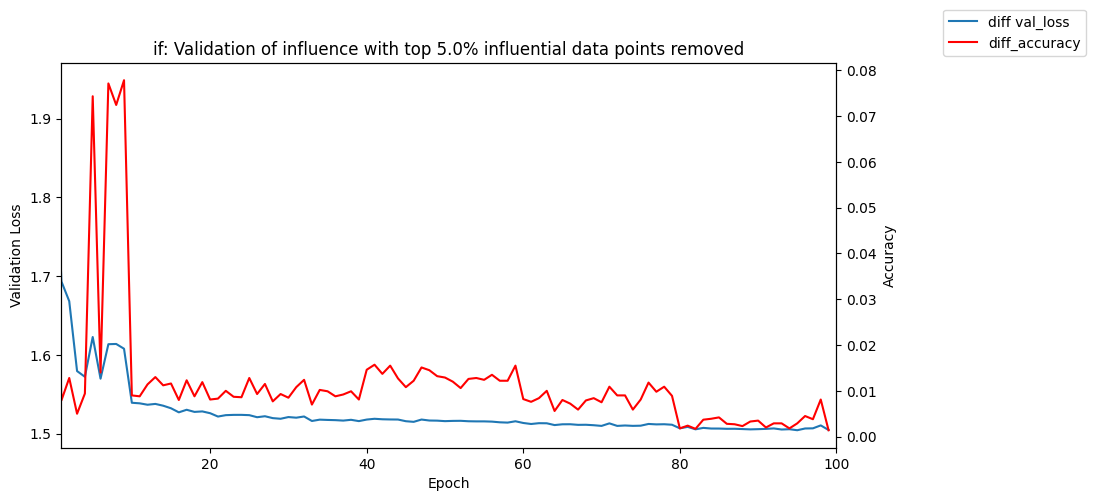

In [15]:
for scoring_method in scoring_methods:
    diff_val_loss = concat_ckpt_metrics(validate_dict[f"validate_validation_losses_{scoring_method}"], checkpoint_labels) - concat_ckpt_metrics(rand_dict[f"rand_validate_train_losses_{scoring_method}"], checkpoint_labels) # suppose positive
    diff_accuracy = concat_ckpt_metrics(rand_dict[f"rand_validate_accuracies_{scoring_method}"], checkpoint_labels) - concat_ckpt_metrics(validate_dict[f"validate_accuracies_{scoring_method}"], checkpoint_labels) # suppose positive
    plot_loss_acc_difference(diff_val_loss, diff_accuracy, scoring_method=f"{scoring_method}", p=p)

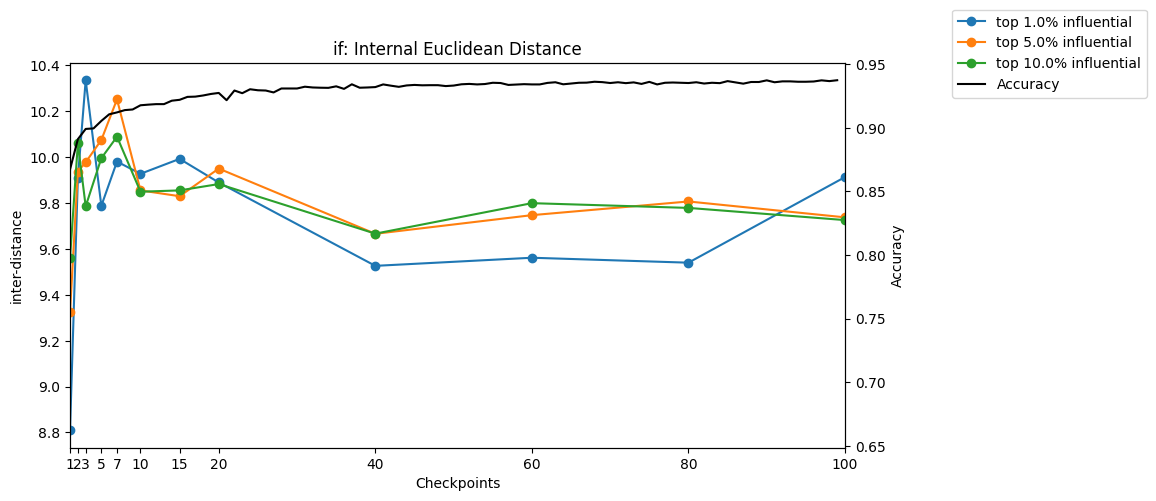

In [ ]:
ls_p = [0.01, 0.05, 0.1]

for k in range(len(scoring_methods)):
    ls_int_distances = calc_pairwise_euclideans(influences_methods[k], mnist_train, ls_p)
    kwargs = {
        "title": f"{scoring_methods[k]}: Internal Euclidean Distance",
        "y_label": "inter-distance",
        "data": ls_int_distances,
        "legend_labels": [f"top {prob*100}% influential" for prob in ls_p]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

100%|██████████| 12/12 [00:05<00:00,  2.31it/s]


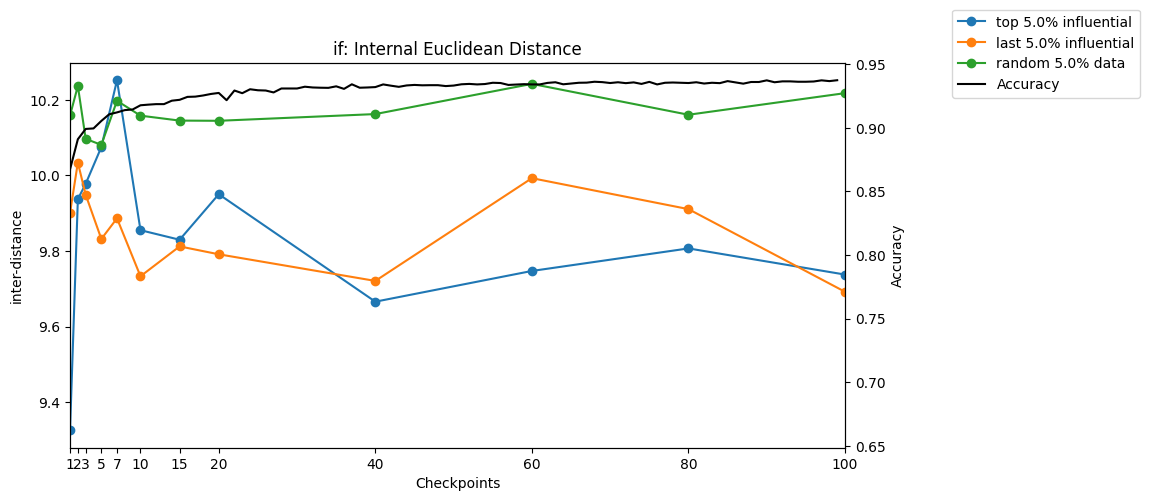

In [ ]:
p = 0.05
# p = 0.1
embeds_dict = generate_embed_dict(p)
for k in range(len(scoring_methods)):
    topinf_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[k]]["top"])
    lastinf_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[k]]["last"])
    rand_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[k]]["random"])
    randlarge_int_distances = create_inf_int_distances(embeds_dict[scoring_methods[k]]["random_large"])

    kwargs = {
        "title": f"{scoring_methods[k]}: Internal Euclidean Distance",
        "y_label": "inter-distance",
        "data": [topinf_int_distances, lastinf_int_distances, rand_int_distances],
        "legend_labels": [f"top {p*100}% influential", f"last {p*100}% influential", f"random {p*100}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

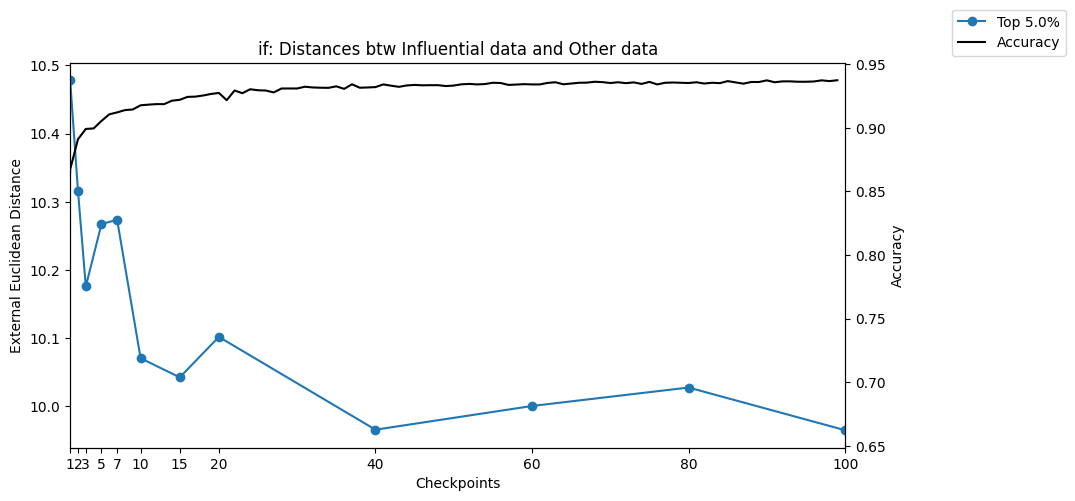

In [ ]:
# Euclidean distance from influential points to other points
for k in range(len(scoring_methods)):
    distances = calc_dist_inf_to_others(select_inf_embeds = embeds_dict[scoring_methods[k]]["top"], 
                                        other_inf_embeds = embeds_dict[scoring_methods[k]]["random_large"])

    kwargs = {
        "title": f"{scoring_methods[k]}: Distances btw Influential data and Other data",
        "y_label": "External Euclidean Distance",
        "data": [distances],
        "legend_labels": [f"Top {p*100}%"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

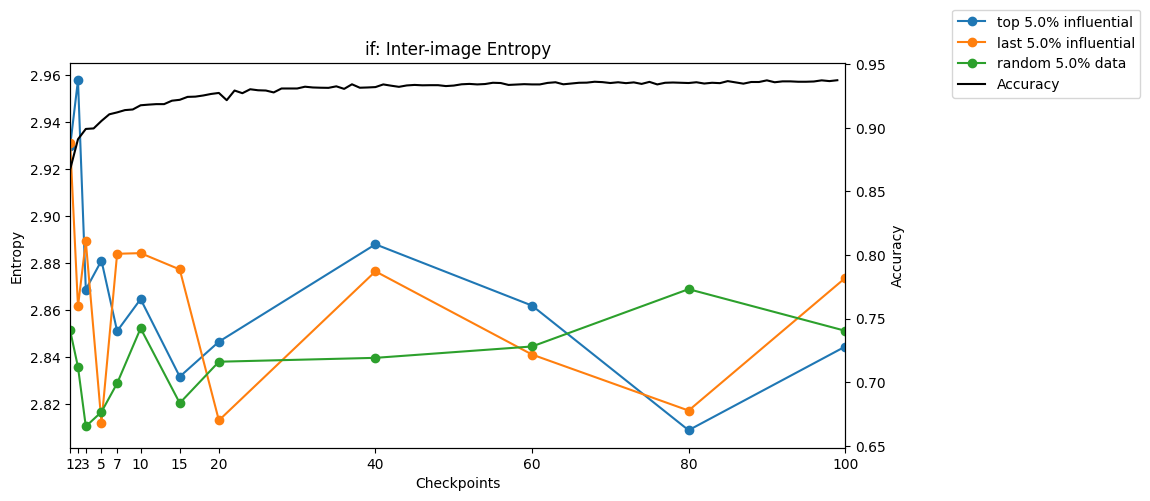

In [ ]:
for k in range(len(scoring_methods)):
    topinf_entropies = create_inter_entropies(embeds_dict[scoring_methods[k]]["top"])
    lastinf_pw_entropies = create_inter_entropies(embeds_dict[scoring_methods[k]]["last"])
    rand_pw_entropies = create_inter_entropies(embeds_dict[scoring_methods[k]]["random"])
    # rand_pw_large_entropies = create_inter_entropies(embeds_dict[scoring_methods[i]]["random_large"])
    
    kwargs = {
        "title": f"{scoring_methods[k]}: Inter-image Entropy",
        "y_label": "Entropy",
        "data": [topinf_entropies, lastinf_pw_entropies, rand_pw_entropies],
        "legend_labels": [f"top {p*100}% influential", f"last {p*100}% influential", f"random {p*100}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

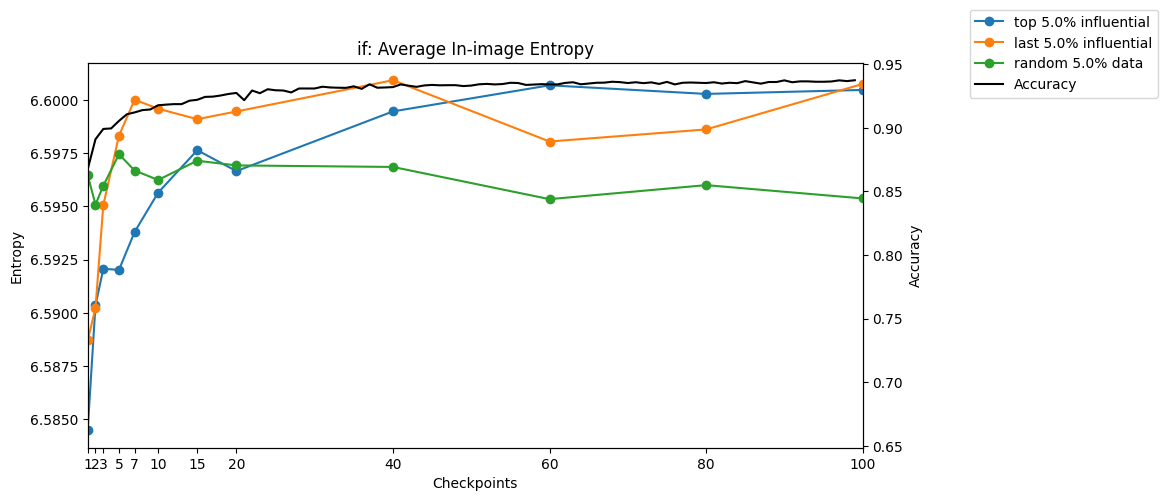

In [ ]:
for k in range(len(scoring_methods)):
    topinf_entropies = create_inner_entropies(embeds_dict[scoring_methods[k]]["top"])
    lastinf_pw_entropies = create_inner_entropies(embeds_dict[scoring_methods[k]]["last"])
    rand_pw_entropies = create_inner_entropies(embeds_dict[scoring_methods[k]]["random"])
    rand_pw_large_entropies = create_inner_entropies(embeds_dict[scoring_methods[k]]["random_large"])

    kwargs = {
        "title": f"{scoring_methods[k]}: Average In-image Entropy",
        "y_label": "Entropy",
        "data": [topinf_entropies, lastinf_pw_entropies, rand_pw_entropies],
        "legend_labels": [f"top {p*100}% influential", f"last {p*100}% influential", f"random {p*100}% data", f"random {p*100*10}% data"]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

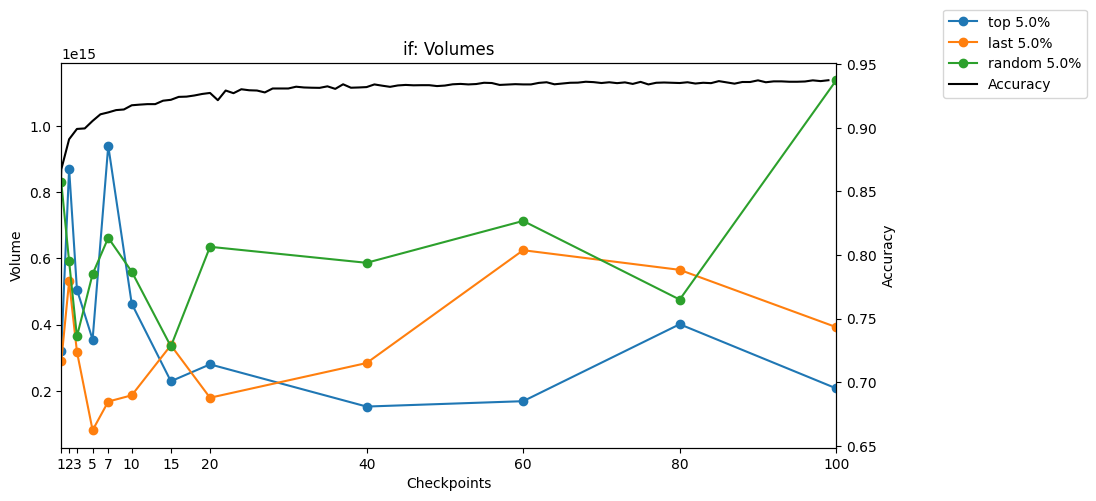

In [ ]:
labels = ["top", "last", "random"]

for k in range(len(scoring_methods)):
    ls_volumes = calc_volumes([embeds_dict[scoring_methods[k]]["top"], embeds_dict[scoring_methods[k]]["last"], embeds_dict[scoring_methods[k]]["random"]])
    kwargs = {
        "title": f"{scoring_methods[k]}: Volumes",
        "y_label": "Volume",
        "data": ls_volumes,
        "legend_labels": [f"{label} {p*100}%" for label in labels]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

# Loss and Accuracy

In [22]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device: ", device)

Device:  cpu


In [23]:
class DigitNet(nn.Module):
    def __init__(self, input_dimensions=784, num_classes=10): 
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dimensions, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
            nn.Softmax(dim=-1)
            )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.model(x)

In [24]:
def plot_get_losses(ls_embeds, legend_labels, losses):
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.set_xlim(min(x_vals), max(x_vals))
    for j, ckpts_embeds in enumerate(ls_embeds):
        train_losses = [] # CrossEntropy loss
        for i, embeds in enumerate(ckpts_embeds):
            checkpoint = checkpoints_filepaths[i]
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
            expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
            optimizer = torch.optim.Adam(DigitNet().parameters(), lr=0.0001)
            # print(f"Loading checkpoint {checkpoint}")
            model, optimizer, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
            loss_fn = nn.CrossEntropyLoss()
            outputs = model(inputs)
            loss = loss_fn(outputs, expect_val)
            train_losses.append(loss.item())
        ax1.plot(checkpoint_labels, train_losses, 'o-', 
                label=f"{legend_labels[j]} {p*100}% train loss")

    plt.title("Train loss (CrossEntropyLoss)")
    ax1.set_xlabel("Checkpoint")
    ax1.set_ylabel("Loss")
    ax1.set_xticks(checkpoint_labels)
    ax1.plot(losses, label="train loss", color='k')

    fig.legend(loc='upper left', bbox_to_anchor=(1,1))
    plt.show()

def plot_get_accs(ls_embeds, legend_labels, train_accuracies):
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.set_xlim(min(x_vals), max(x_vals))

    for j, ckpts_embeds in enumerate(ls_embeds):
        accuracies = []
        
        for i, embeds in enumerate(ckpts_embeds):
            checkpoint = checkpoints_filepaths[i]
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
            expect_val = torch.tensor([embed[1] for embed in embeds], device=device).unsqueeze(1)
            optimizer = torch.optim.Adam(DigitNet().parameters(), lr=0.0001)
            model, optimizer, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
            outputs = model(inputs)
            predictions = (outputs > 0.5).int()
            accuracy = (predictions == expect_val).sum() / len(expect_val)
            accuracies.append(accuracy.cpu())
        ax1.plot(checkpoint_labels, accuracies, 'o-', 
                label=f"{legend_labels[j]} {p*100}% accuracy")

    plt.title("Training data accuracy")
    ax1.set_xlabel("Checkpoint")
    ax1.set_ylabel("Accuracy")
    ax1.set_xticks(checkpoint_labels)
    ax1.plot(train_accuracies, label="Accuracy", color='k')

    fig.legend(loc='upper left', bbox_to_anchor=(1,1))
    plt.show()

## For IF

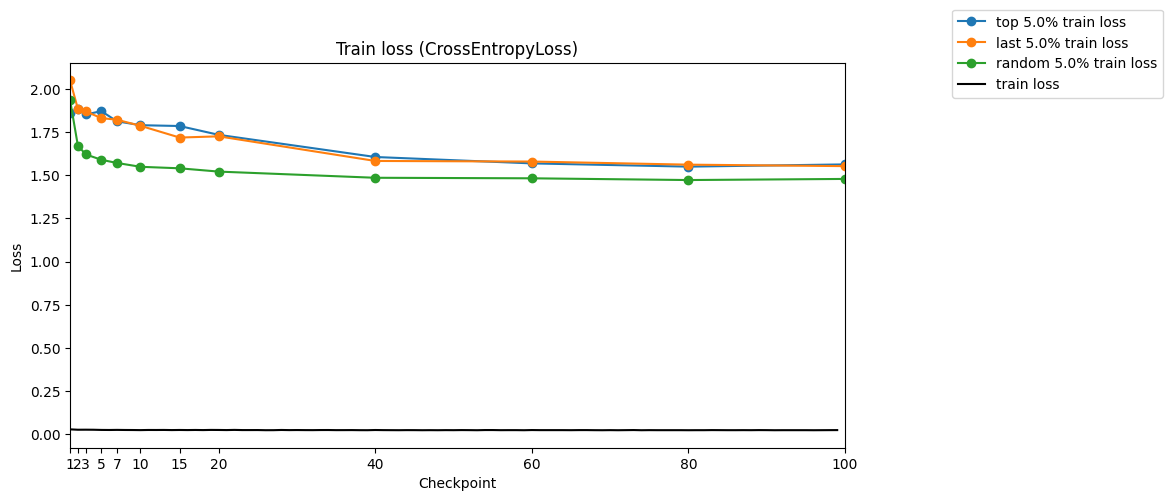

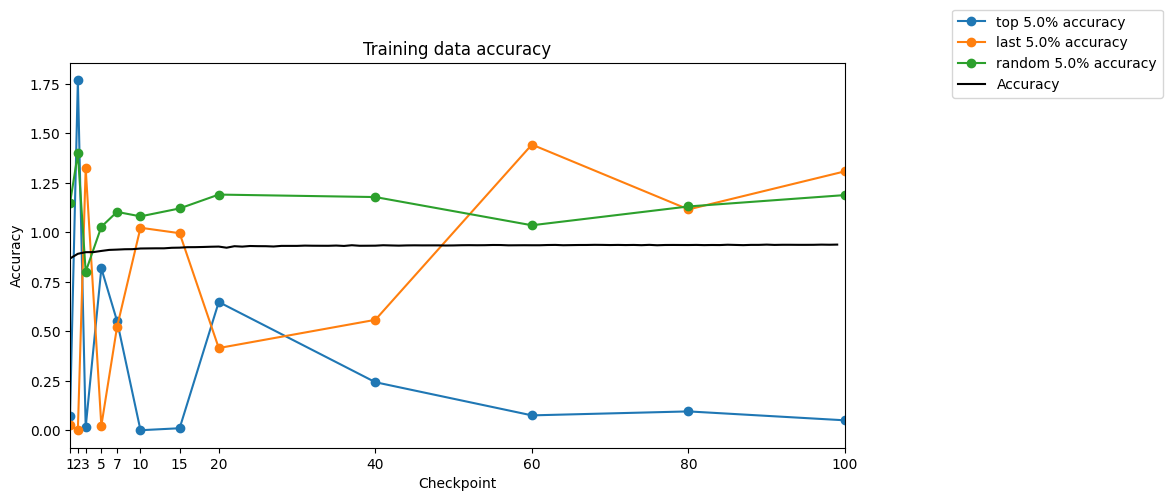

In [25]:
labels = ["top", "last", "random"]
ls_embeds = [embeds_dict["if"]["top"],
             embeds_dict["if"]["last"],
             embeds_dict["if"]["random"]]
plot_get_losses(ls_embeds, labels, train_losses)
plot_get_accs(ls_embeds, labels, accuracies)

## For TracIn

In [26]:
labels = ["top", "last", "random"]
ls_embeds = [embeds_dict["tracin"]["top"],
             embeds_dict["tracin"]["last"],
             embeds_dict["tracin"]["random"]]
plot_get_losses(ls_embeds, labels, train_losses)
plot_get_accs(ls_embeds, labels, accuracies)

KeyError: 'tracin'

In [ ]:
# Least influtial points qualitative check
def plot_img(embeds, num_cols=10):
    fig, ax = plt.subplots(len(embeds), 10, figsize=(20, 20))
    for i in range(len(embeds)):
        for j in range(num_cols):
            ax[i, j].imshow(embeds[i][j][0].reshape(28, 28))
            ax[i, j].axis('off')
            ax[i, j].set_title(f"Label: {embeds[i][j][1]}")
    plt.tight_layout()
    plt.show()

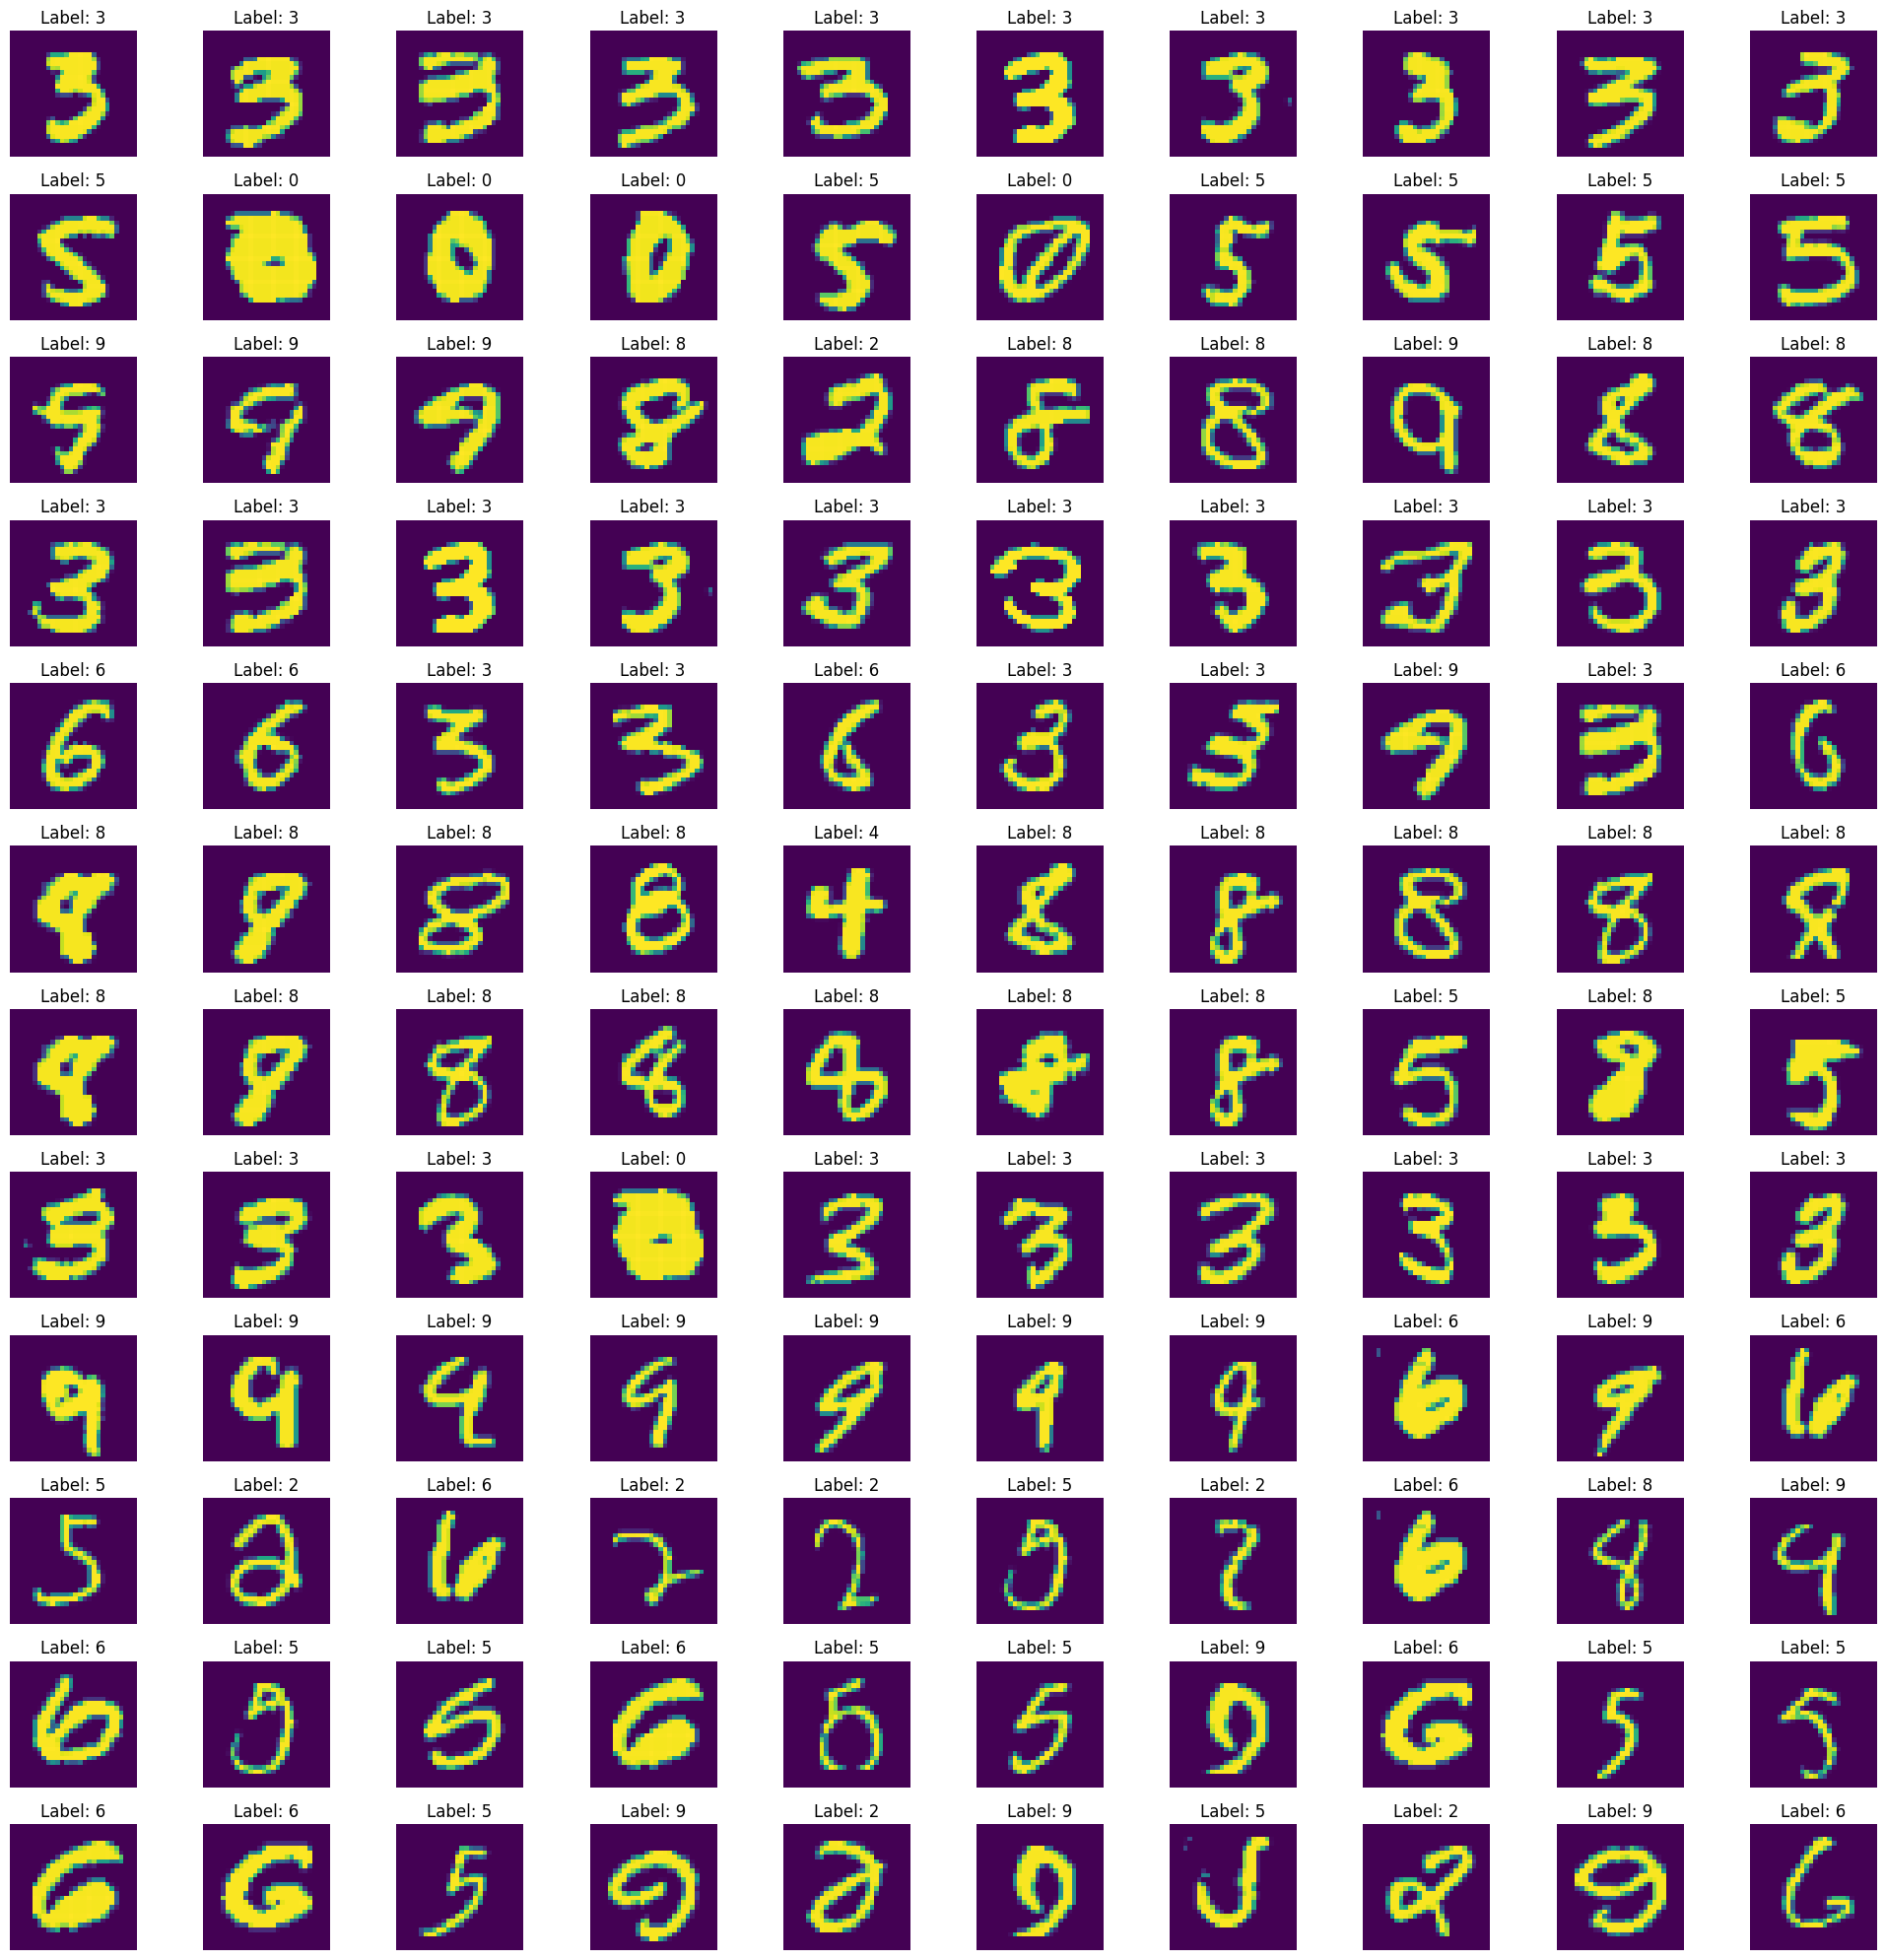

In [ ]:
plot_img(embeds_dict["if"]["top"])

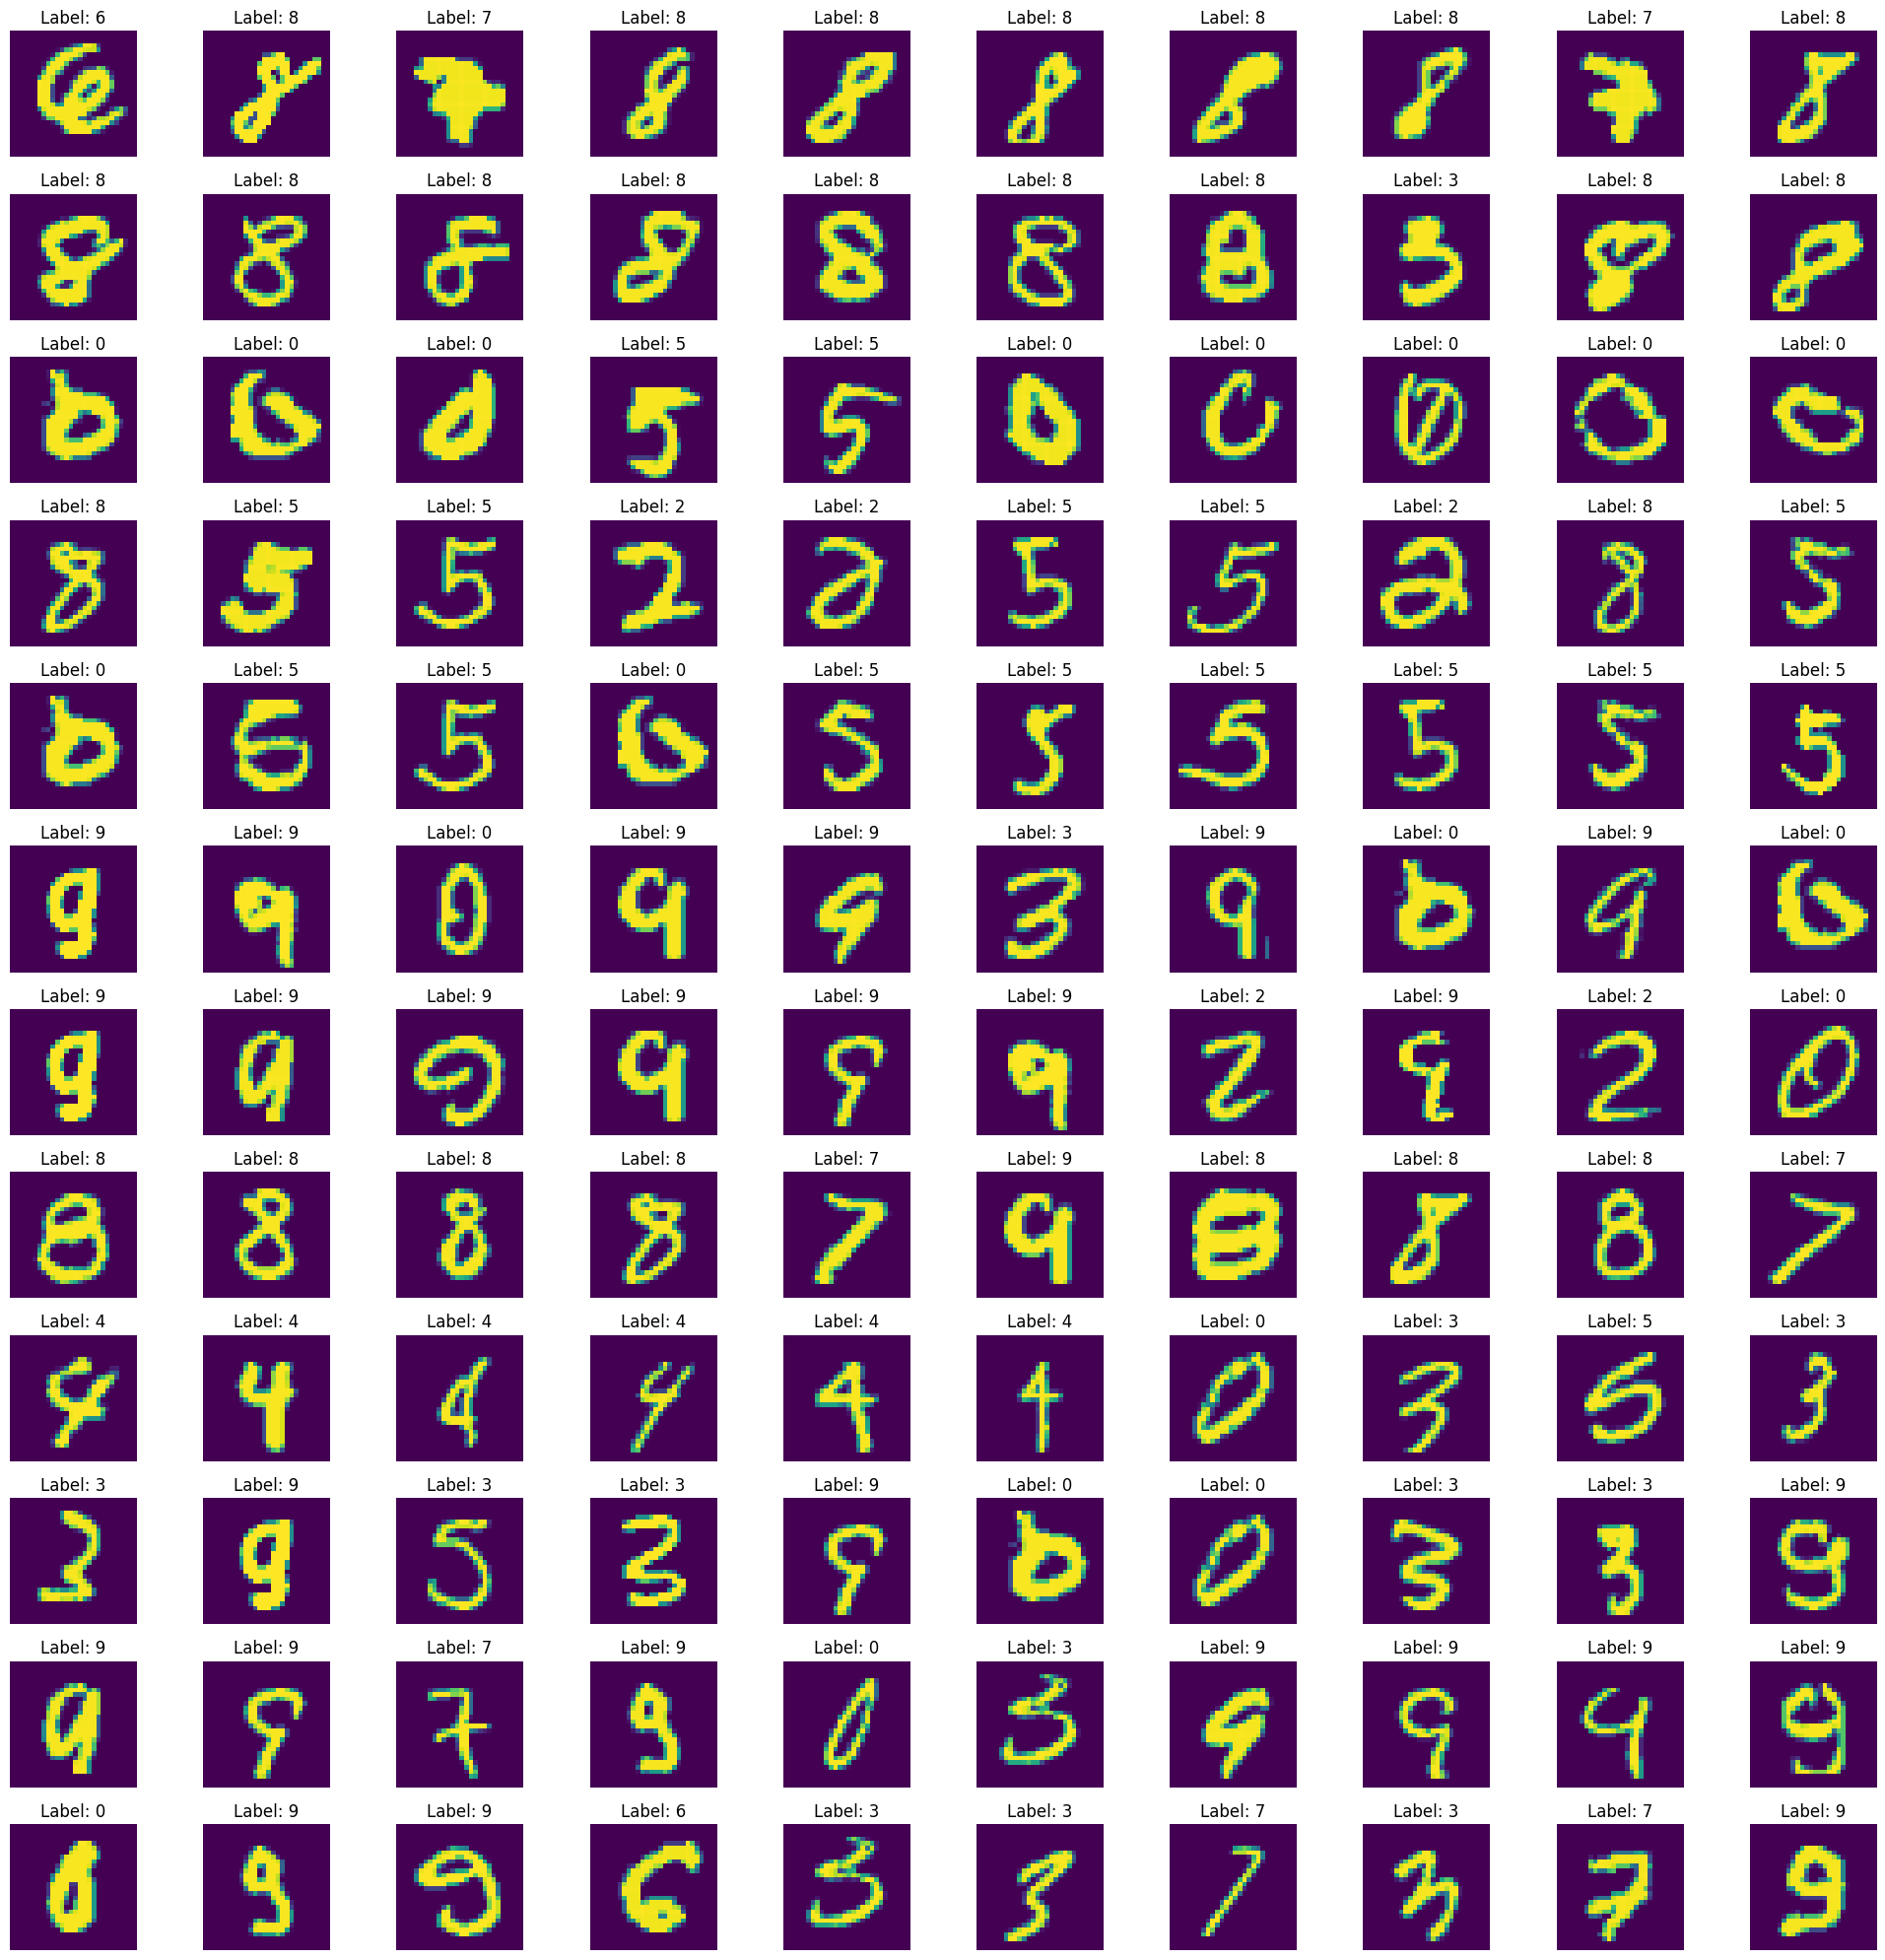

In [ ]:
plot_img(embeds_dict["if"]["last"])

In [ ]:
plot_img(embeds_dict["tracin"]["top"])

In [ ]:
plot_img(embeds_dict["tracin"]["last"])

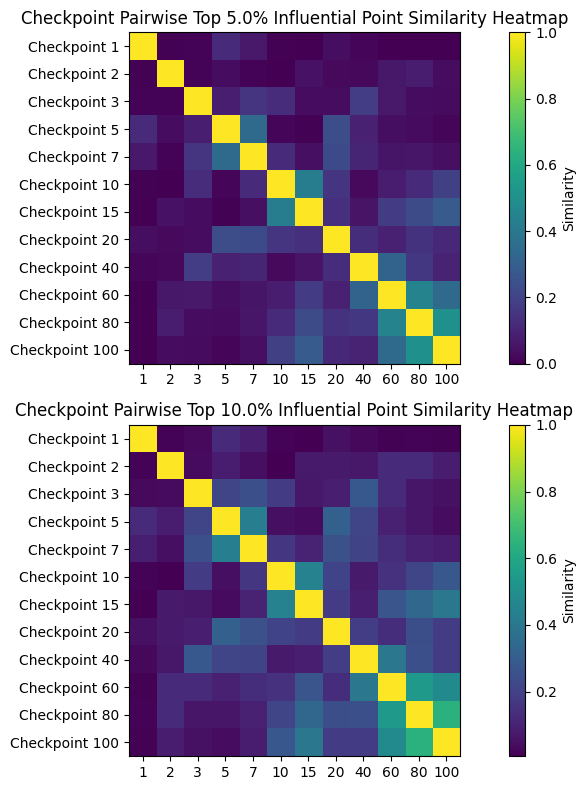

In [ ]:
for k in range(len(scoring_methods)):
    pw_similarities_lowp = pairwise_similarity(top_inf_indices(influences_methods[k], int(p*num_data)))
    pw_similarities_highp = pairwise_similarity(top_inf_indices(influences_methods[k], int(0.1*num_data)))

    plot_similar_indices(pw_similarities_lowp, pw_similarities_highp, checkpoint_labels, p)

# Decision Boundary

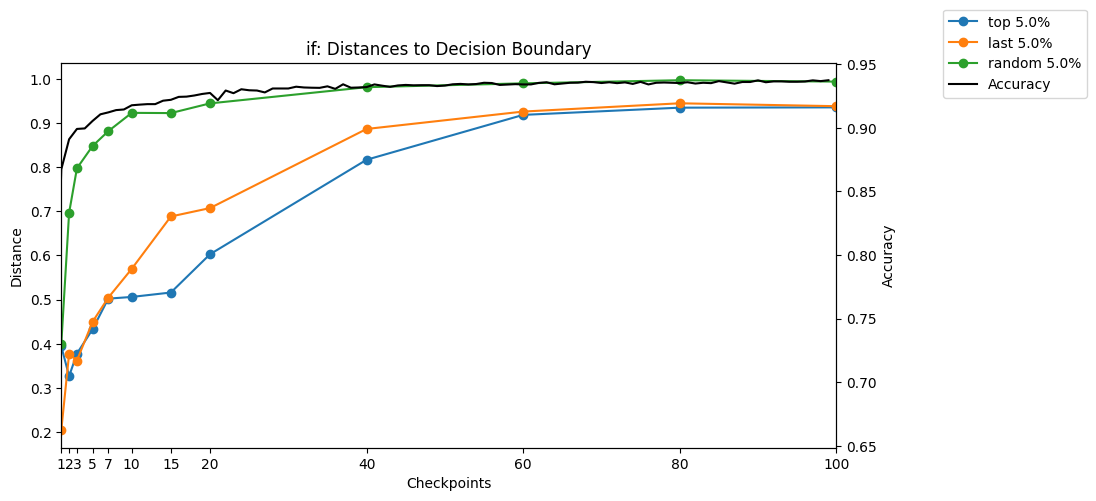

In [35]:
optimizer = torch.optim.Adam(DigitNet().parameters(), lr=0.0001)
for i in range(len(scoring_methods)):
    dist_lst = []
    for j, ckpts_embeds in enumerate([embeds_dict[scoring_methods[i]]["top"], embeds_dict[scoring_methods[i]]["last"], embeds_dict[scoring_methods[i]]["random"]]):
        distance_to_dec_boundary = []
        
        for k, embeds in enumerate(ckpts_embeds):
            checkpoint = checkpoints_filepaths[k]
            inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
            model, optimizer, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
            outputs = model(inputs)
            top_logits = torch.sort(outputs, descending=True, dim=-1).values
            distances = torch.mean(top_logits[:, 0] - top_logits[:, 1])
            distance_to_dec_boundary.append(distances.item())
        dist_lst.append(distance_to_dec_boundary)
    kwargs = {
        "title": f"{scoring_methods[i]}: Distances to Decision Boundary",
        "y_label": "Distance",
        "data": dist_lst,
        "legend_labels": [f"{label} {p*100}%" for label in labels]
    }
    plot_var_acc_legends(x_vals, checkpoint_labels, accuracies, **kwargs)

Plotting Decision Boundary: 100%|██████████| 12/12 [00:02<00:00,  5.39it/s]


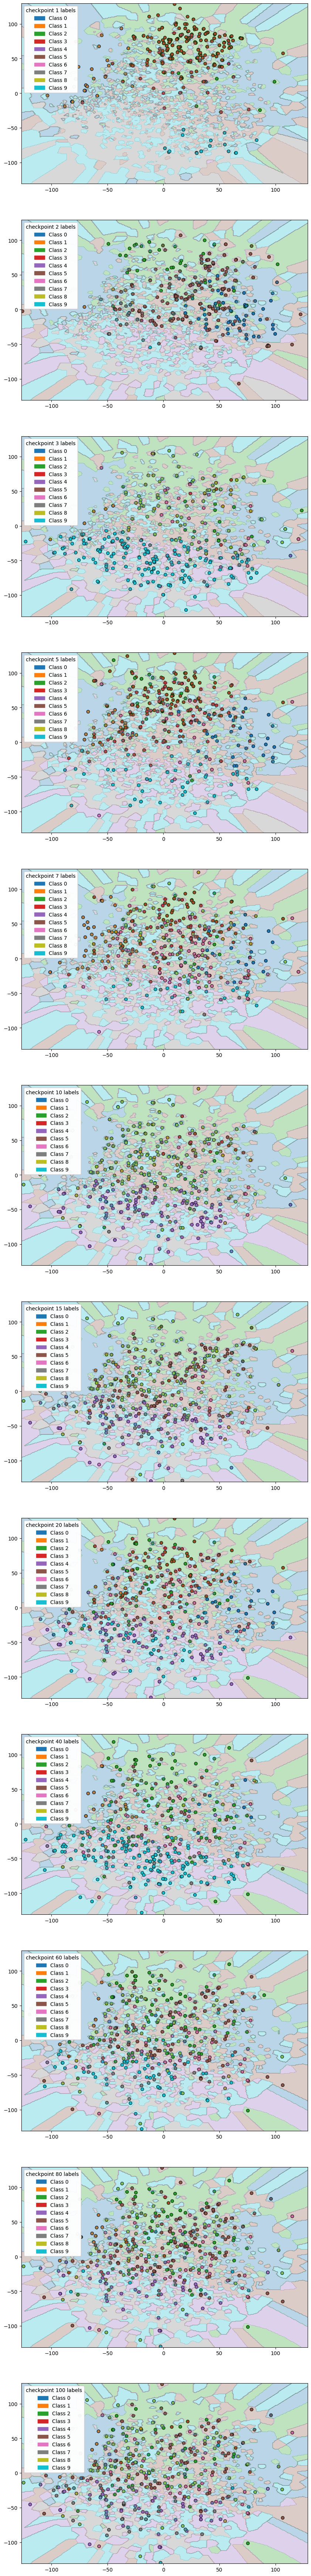

In [ ]:
for k in range(len(scoring_methods)):
    ckpts_top_inf_indices = top_inf_indices(mnist_influence_if, int(p*num_data))
    all_x_2d, all_data_y, all_data_x = tsne_all_dataset(mnist_train)
    fig, ax = plt.subplots(len(checkpoint_labels), 1, figsize=(10, 90))
    custom_cmap = plt.get_cmap('tab10')
    norm = mcolors.Normalize(vmin=0, vmax=9)
    for k, ckpt_top_inf_indices in tqdm(enumerate(ckpts_top_inf_indices), desc='Plotting Decision Boundary', total=len(checkpoint_labels)):
        model, _, _, _ = load_checkpoint(DigitNet().to(device), torch.optim.Adam(DigitNet().parameters(), lr=0.0001), checkpoints_filepaths[k])
        output = model(torch.tensor(all_data_x, dtype=torch.float32, device=device))
        all_y_pred = torch.argmax(output, dim=-1).flatten()
        plt_decision_boundary(ckpt_top_inf_indices, checkpoint_labels, all_x_2d, all_data_y, all_y_pred, ax[k], k, custom_cmap, norm)
    # fig.tight_layout()
    plt.show()